# HW2 — Multiple Object Video Detection (VisDrone)
**Authors:** Sofiia Sychak, Sofiia Vitchynkina

In [1]:
# %pip install -r ../requirements.txt
# %pip install -e ..

In [2]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
import pandas as pd
from ultralytics import RTDETR, YOLO

from hw2.analysis import defense
from hw2.analysis.defense import show_source
from hw2.config import load_config
from hw2.data import boxes, prepare
from hw2.eval import coco_eval
from hw2.infer import temporal
from hw2.models import frcnn, patches_tv, retinanet
from hw2.paths import repo_root
from hw2.train import run_ultralytics

pd.set_option("display.precision", 4, "display.max_columns", 20, "display.width", 200)
FINALS = ["Q0", "QF"]  # our two kaggle picks

## 1. Data
VisDrone2019-VID: drone video clips with 8 classes, many tiny and crowded objects, and *ignore regions* where nothing is labelled. We load the original val annotations and the test frame list and look at class counts, object sizes and objects per frame.

In [3]:
coco = defense.load_val_coco()
objects = defense.object_table(coco) if coco else None
defense.size_table(objects) if coco else None

,objects,median_side,small,medium,large
class,,,,,
person,50312,47.3,24.7,71.8,3.4
bicycle,6022,66.7,2.9,85.6,11.5
car,31821,63.6,9.4,70.7,19.9
van,6842,61.4,5.8,71.4,22.8
truck,1359,94.7,2.8,48.4,48.8
tricycle,5487,49.9,18.5,59.0,22.4
bus,264,93.4,0.0,51.5,48.5
motor,12025,35.7,40.4,55.1,4.5


,count,mean,std,min,25%,50%,75%,max
objects per frame,2846.0,40.1,26.8,8.0,16.0,37.0,51.8,116.0


,,clips,frames
width,height,,
1360,764,18,1474
1920,1080,11,991
1344,756,7,441
680,382,3,321
1904,1072,4,305
960,540,5,279


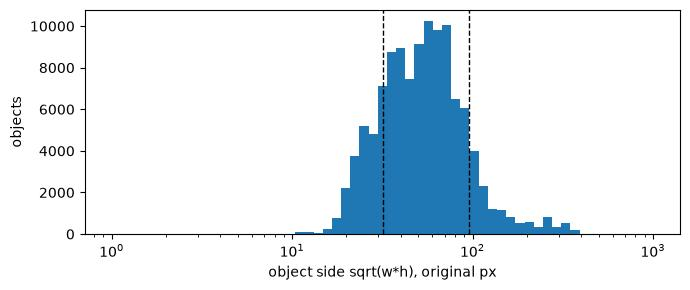

In [4]:
defense.plot_sizes(objects);
display(defense.per_frame_table(coco, objects))
defense.sizes_of_test_set()

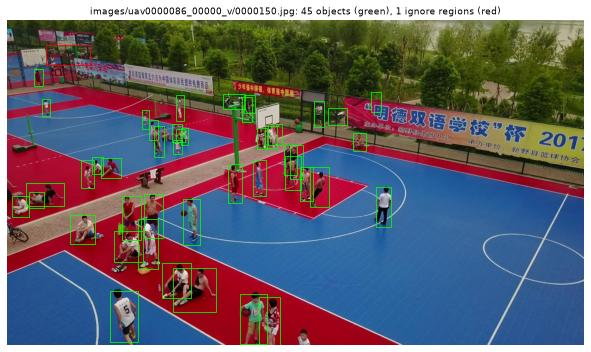

In [5]:
defense.plot_gt_frame(coco, index=defense.frame_with_ignore(coco));

Notes:

## 2. Preprocessing
Neighbouring frames are almost identical, so training uses every 5th frame. Ignore regions are painted grey (114) so the model is not punished for unlabelled objects there, boxes are clipped to the frame, and frames are capped at 1920 px on the long side.

In [6]:
show_source(prepare.build_tasks)

def build_tasks(
    splits: Sequence[str], settings: Settings, data_dir: Path, out_dir: Path, max_clips: int | None = None
) -> list[ClipTask]:
    """Load each needed source COCO file once and return clip tasks ordered by split and clip."""
    tasks: list[ClipTask] = []
    for source in sorted({SPLITS[s].source for s in splits}):
        coco = cu.load_coco(data_dir / source / "annotations_coco.json")
        clips = cu.frames_by_clip(coco["images"])
        names = sorted(clips)[:max_clips]
        chosen = {
            split: {clip: clips[clip][:: settings.steps[split]] for clip in names}
            for split in splits
            if SPLITS[split].source == source
        }
        wanted = {im["id"] for per_clip in chosen.values() for frames in per_clip.values() for im in frames}
        by_image = cu.annotations_by_image(coco["annotations"], wanted)
        del coco
        for split, per_clip in chosen.items():
            for clip, frames in per_clip.items():
                pairs = [(im, by_image.get(im["id"], [])) for im in frames]
                tasks.append(ClipTask(split, clip, data_dir / source, out_dir, pairs, settings))
    order = list(SPLITS)
    return sorted(tasks, key=lambda t: (order.index(t.split), t.clip))

In [7]:
show_source(boxes.paint_rects)

def paint_rects(image: np.ndarray, rects: np.ndarray, fill: int) -> None:
    """Fill pixel rectangles of an image in place with a constant value."""
    for x1, y1, x2, y2 in rects:
        image[y1:y2, x1:x2] = fill

In [8]:
show_source(boxes.clean_boxes)

def clean_boxes(
    boxes: ArrayLike,
    src_size: tuple[int, int],
    out_size: tuple[int, int],
    mask: np.ndarray | None = None,
    max_ignore_frac: float = 0.5,
    min_size: float = 1.0,
) -> CleanBoxes:
    """Clip corner boxes to the source frame, drop mostly masked ones, scale them and drop tiny ones."""
    (src_w, src_h), (out_w, out_h) = src_size, out_size
    raw = as_boxes(boxes)
    clipped = clip_xyxy(raw, src_w, src_h)
    n_clipped = int((clipped != raw).any(axis=1).sum())
    keep = np.ones(len(raw), dtype=bool)
    if mask is not None and mask.any():
        keep = covered_fraction(clipped, mask) <= max_ignore_frac
    n_ignore = int((~keep).sum())
    scaled = scale_xyxy(clipped, out_w / src_w, out_h / src_h)
    big = (scaled[:, 2] - scaled[:, 0] >= min_size) & (scaled[:, 3] - scaled[:, 1] >= min_size)
    n_small = int((keep & ~big).sum())
    idx = np.flatnonzero(keep & big)
    return CleanBoxes(idx, scaled[idx], n_clipped, n_ignore, n_small)

In [9]:
defense.subsample_table(coco, step=5).head(3)

,frames,kept,first kept
uav0000086_00000_v,464,93,"[1, 6, 11, 16]"
uav0000117_02622_v,349,70,"[1, 6, 11, 16]"
uav0000137_00458_v,233,47,"[1, 6, 11, 16]"


,boxes,kept,clipped,dropped in ignore,dropped tiny
uav0000086_00000_v,45,45,0,0,0


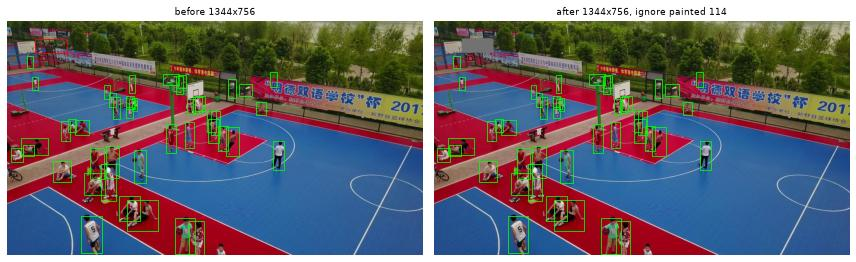

In [10]:
fig, counts = defense.preprocess_frame(coco, index=defense.frame_with_ignore(coco))
counts

Notes:

## 3. Validation and metric
The split is by sequence: the 7 val clips never appear in training. The metric is COCO mAP@[.5:.95] with up to 500 boxes per image and ignore regions as crowd. As a sanity check, ground truth used as predictions must score mAP 1.0.

In [11]:
show_source(coco_eval.evaluate)

def evaluate(
    preds: pd.DataFrame | str | Path,
    gt_json: GroundTruth,
    max_dets: int = MAX_DETS,
    backend: str | None = None,
    breakdown: bool = True,
) -> dict[str, Any]:
    """Evaluate predictions against COCO ground truth at max_dets boxes per image and return all metrics."""
    gt = load_gt(gt_json)
    preds = validate_preds(preds) if isinstance(preds, pd.DataFrame) else load_preds(preds)
    image_ids = match_frames(preds["file_name"], gt_frame_index(gt["images"]), "ground-truth")
    dets = top_k_per_image(preds.assign(image_id=image_ids), max_dets, by="image_id")
    name, coco_cls, eval_cls = coco_backend(backend)
    with contextlib.redirect_stdout(io.StringIO()):
        coco_gt = build_coco(coco_cls, gt)
        coco_dt = build_coco(coco_cls, det_dataset(dets, gt))

        def evaluate_ids(ids: Sequence[int]) -> dict[str, Any]:
            """Summarize COCOeval on one subset of images."""
            return summarize(run_cocoeval(eval_cls, coco_gt, coco_dt, ids, max_dets), max_dets)

        metrics = evaluate_ids([int(img["id"]) for img in gt["images"]])
        if breakdown:
            clips, density = image_groups(gt)
            metrics["per_clip"] = subset_map(evaluate_ids, clips)
            metrics["per_density"] = subset_map(evaluate_ids, density)
            metrics["density_images"] = {label: len(ids) for label, ids in density.items()}
    metrics.update(backend=name, max_dets=max_dets, n_images=len(gt["images"]), n_preds=len(dets))
    return metrics

In [12]:
preds, gt = defense.gt_as_predictions(coco, clip="uav0000086_00000_v")
metrics = coco_eval.evaluate(preds, gt, breakdown=False)
{key: round(metrics[key], 4) for key in ("map", "map50", "map75", "ar500", "n_images")}

{'map': 1.0, 'map50': 1.0, 'map75': 1.0, 'ar500': 1.0, 'n_images': 464}

In [13]:
defense.validation_table()

,val mAP,testlike mAP,gap,LB
exp,,,,
F0,0.2080,0.1941,-0.0139,NaN
F1,0.2076,0.1975,-0.0101,NaN
R0,0.1788,0.1678,-0.0110,NaN
R1,0.1685,0.1566,-0.0119,NaN
A2,0.1636,0.1555,-0.0081,0.1887
A0,0.1621,0.1582,-0.0039,0.1842


Notes:

## 4. Two-stage detector: Faster R-CNN
A region proposal network suggests boxes from anchors, then RoI heads classify and refine them. F0 uses torchvision anchors (32-512); F1 uses smaller anchors (16-256) for tiny objects. A GIoU box loss is available as a patch.

In [14]:
show_source(frcnn.build_frcnn)

def build_frcnn(cfg: Mapping[str, Any], pretrained: bool = True) -> FasterRCNN:
    """Build Faster R-CNN v2 from COCO weights with one anchor size per FPN level and a new 9-label predictor."""
    settings = frcnn_settings(cfg)
    kwargs = {key: value for key, value in settings.items() if key not in BUILD_ONLY}
    weights = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1 if pretrained else None
    model = fasterrcnn_resnet50_fpn_v2(weights=weights, weights_backbone=None, **kwargs)
    sizes = tuple((int(size),) for size in settings["anchor_sizes"])
    model.rpn.anchor_generator = AnchorGenerator(sizes, (ASPECT_RATIOS,) * len(sizes))
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_LABELS)
    return model

In [15]:
show_source(patches_tv.giou_fastrcnn_loss)

def giou_fastrcnn_loss(
    class_logits: Tensor,
    box_regression: Tensor,
    labels: Sequence[Tensor],
    regression_targets: Sequence[Tensor],
    weights: tuple[float, float, float, float] = RCNN_WEIGHTS,
) -> tuple[Tensor, Tensor]:
    """Return torchvision's classification loss and a GIoU loss of positive RoI deltas decoded on one shared box."""
    classification_loss, _ = ORIGINAL_FASTRCNN_LOSS(class_logits, box_regression, labels, regression_targets)
    all_labels = torch.cat(list(labels), dim=0)
    targets = torch.cat(list(regression_targets), dim=0)
    positive = torch.where(all_labels > 0)[0]
    deltas = box_regression.reshape(len(all_labels), -1, 4)[positive, all_labels[positive]].float()
    coder = BoxCoder(weights)
    reference = deltas.new_tensor(REFERENCE_BOX).expand(len(positive), 4)
    target_boxes = coder.decode_single(targets[positive].float(), reference)
    box_loss = _box_loss("giou", coder, reference, target_boxes, deltas)
    return classification_loss, box_loss / all_labels.numel()

In [16]:
cfgs = {exp: load_config(defense.config_path(exp)) for exp in ["F0", "F1"]}
models = {exp: frcnn.build_frcnn(cfg, pretrained=False) for exp, cfg in cfgs.items()}
pd.concat([defense.detector_summary(models[exp], cfgs[exp]) for exp in models], axis=1)

,F0,F1
anchor sizes,"((32,), (64,), (128,), (256,), (512,))","((16,), (32,), (64,), (128,), (256,))"
aspect ratios,"(0.5, 1.0, 2.0)","(0.5, 1.0, 2.0)"
rpn pre-nms train/test,"(2000, 1000)","(2000, 1000)"
rpn post-nms train/test,"(2000, 1000)","(2000, 1000)"
roi samples/img,512,512
roi positive fraction,0.25,0.25
box loss,smooth_l1,smooth_l1
params (M),43.29,43.29


In [17]:
defense.experiment_table("frcnn")

frcnn: no results json for F2, F3


,name,mAP,AP50,APs,APm,APl,AR500,testlike mAP,train h,epochs,ms/img,LB
exp,,,,,,,,,,,,
F0,F0_frcnn_base,0.2080,0.4269,0.1014,0.2002,0.3744,0.4218,0.1941,2.43,9.4,267.2,NaN
F1,F1_frcnn_anchors16,0.2076,0.4387,0.0895,0.1928,0.3839,0.4151,0.1975,2.43,9.3,257.2,NaN


Notes:

## 5. One-stage anchor-based: RetinaNet
Dense classification and box regression on every anchor, with focal loss against the huge number of easy background anchors. R0 is the default; R1 uses k-means anchor ratios. The box loss and focal parameters are configurable via patches.

In [18]:
show_source(retinanet.build_retinanet)

def build_retinanet(cfg: Mapping[str, Any], pretrained: bool = True) -> RetinaNet:
    """Build RetinaNet v2 from COCO weights with 9 anchors per location, new 9-label logits and the chosen box loss."""
    settings = retinanet_settings(cfg)
    kwargs = {key: value for key, value in settings.items() if key not in BUILD_ONLY}
    weights = RetinaNet_ResNet50_FPN_V2_Weights.COCO_V1 if pretrained else None
    model = retinanet_resnet50_fpn_v2(weights=weights, weights_backbone=None, **kwargs)
    sizes = anchor_sizes(settings["anchor_base_sizes"])
    model.anchor_generator = AnchorGenerator(sizes, (tuple(settings["anchor_ratios"]),) * len(sizes))
    reset_class_logits(model.head.classification_head, NUM_LABELS)
    regression = model.head.regression_head
    LOG.info("retinanet regression loss: torchvision %s, config %s", regression._loss_type, settings["regression_loss"])
    regression._loss_type = settings["regression_loss"]
    return model

In [19]:
show_source(patches_tv.configure_patches)

def configure_patches(cfg: Mapping[str, Any], model: torch.nn.Module) -> list[str]:
    """Reset both patches, then apply the ones the config's family and model block ask for and return their names."""
    reset_patches()
    family, settings = cfg.get("family"), cfg.get("model") or {}
    active: list[str] = []
    if family == "frcnn" and settings.get("box_loss") == "giou":
        weights = tuple(model.roi_heads.box_coder.weights)
        tv_roi_heads.fastrcnn_loss = functools.partial(giou_fastrcnn_loss, weights=weights)
        active.append("frcnn_giou")
    focal = {key: settings.get(f"focal_{key}") for key in ("gamma", "alpha")}
    focal = {key: float(value) for key, value in focal.items() if value is not None}
    if family == "retinanet" and focal:
        tv_retinanet.sigmoid_focal_loss = functools.partial(ORIGINAL_FOCAL_LOSS, **focal)
        active.append("retinanet_focal " + " ".join(f"{key}={value}" for key, value in focal.items()))
    LOG.info("torchvision patches: %s", ", ".join(active) or "none")
    return active

In [20]:
cfgs = {exp: load_config(defense.config_path(exp)) for exp in ["R0", "R1"]}
models = {exp: retinanet.build_retinanet(cfg, pretrained=False) for exp, cfg in cfgs.items()}
pd.concat([defense.detector_summary(models[exp], cfgs[exp]) for exp in models], axis=1)

23:03:04 INFO hw2.models.retinanet: retinanet regression loss: torchvision giou, config giou


23:03:04 INFO hw2.models.retinanet: retinanet regression loss: torchvision giou, config giou


,R0,R1
anchor sizes,"((32, 40, 50), (64, 80, 101), (128, 161, 203),...","((16, 20, 25), (32, 40, 50), (64, 80, 101), (1..."
aspect ratios,"(0.5, 1.0, 2.0)","(0.5, 1.0, 2.0)"
fg/bg IoU,"(0.5, 0.4)","(0.5, 0.4)"
box loss,giou,giou
focal gamma/alpha,"(None, None)","(None, None)"
params (M),36.5,36.5


In [21]:
defense.experiment_table("retinanet")

retinanet: no results json for R2, R3


,name,mAP,AP50,APs,APm,APl,AR500,testlike mAP,train h,epochs,ms/img,LB
exp,,,,,,,,,,,,
R0,R0_retina_base,0.1788,0.3476,0.0655,0.1608,0.3363,0.3503,0.1678,2.47,11.5,213.5,NaN
R1,R1_retina_kmeans,0.1685,0.3624,0.0644,0.1543,0.3056,0.3935,0.1566,2.48,11.4,211.7,NaN


Notes:

## 6. Anchor-free: YOLO
YOLO11 predicts boxes directly per grid cell, without anchors. A2 adds a P2 head (stride 4) for small objects; FINAL is yolo11m trained on train_s5 plus val_monitor. Training and prediction go through one Ultralytics runner.

In [22]:
show_source(run_ultralytics.train)

def train(cfg: Mapping[str, Any], run: str, out_dir: Path, device: str, smoke: bool) -> tuple[Path, float]:
    """Train the configured model into out_dir and return its last.pt and the training wall hours."""
    variant = cfg.get("data_variant") or DEFAULT_VARIANT
    data_yaml = write_data_yaml(out_dir / "data.yaml", variant, cfg.get("extra_train") or ())
    (out_dir / "results.csv").unlink(missing_ok=True)
    setup_wandb(run, cfg, out_dir, ddp=gpu_count(device) > 1)
    apply_loss_patch(cfg.get("loss_patch"))
    model = build_model(cfg)
    with Timer(f"train {run}", LOG) as timer:
        model.train(**train_args(cfg, run, data_yaml, device, smoke))
    last = out_dir / "weights" / "last.pt"
    if not last.is_file():
        raise FileNotFoundError(f"training finished without {last}")
    return last, timer.elapsed / 3600

In [23]:
show_source(run_ultralytics.predict_split)

def predict_split(model: Any, split: str, pcfg: Mapping[str, Any], device: str, limit: int | None) -> pd.DataFrame:
    """Predict one split and return boxes in original pixels with top-left x, y, w and h."""
    items = pick(split_images(split), limit)
    names = {str(path.resolve()): name for name, path in items}
    files, classes, scores, boxes = [], [], [], []
    with tempfile.TemporaryDirectory() as tmp:
        source = Path(tmp) / f"{split}.txt"  # list sources preload everything
        source.write_text("".join(f"{path}\n" for _, path in items))
        for result in model.predict(source=str(source), stream=True, verbose=False, device=device, **pcfg):
            found = result.boxes
            files.append(np.full(len(found), names[str(Path(result.path).resolve())], dtype=object))
            classes.append(found.cls.cpu().numpy().astype(np.int64))
            scores.append(found.conf.cpu().numpy().astype(np.float64))
            boxes.append(found.xyxy.cpu().numpy().astype(np.float64).reshape(-1, 4))
    xyxy = np.concatenate(boxes) if boxes else np.zeros((0, 4))
    LOG.info("%s: %d images, %d boxes", split, len(items), len(xyxy))
    return pd.DataFrame({
        "file_name": np.concatenate(files).astype(str) if files else np.array([], dtype=str),
        "class_id": np.concatenate(classes) if classes else np.array([], dtype=np.int64),
        "score": np.concatenate(scores) if scores else np.array([], dtype=np.float64),
        "x": xyxy[:, 0],
        "y": xyxy[:, 1],
        "w": xyxy[:, 2] - xyxy[:, 0],
        "h": xyxy[:, 3] - xyxy[:, 1],
    })

In [24]:
print(defense.config_text(["A0", "A2", "FINAL"]))

== configs/yolo/A0_yolo11s_1280.yaml
# baseline, default augmentation
base: ../ultralytics_base.yaml
family: yolo
model: yolo11s.pt
train:
  time: 2.5
  epochs: 300
  imgsz: 1280
  batch: 8
  close_mosaic: 10
predict:
  imgsz: 1280
== configs/yolo/A2_yolo11s_p2_1280.yaml
# change: extra P2/4 head
base: A0_yolo11s_1280.yaml
model: configs/models/yolo11s-p2.yaml
pretrained: yolo11s.pt
train:
  batch: 6
== configs/yolo/FINAL.yaml
# submission model: At with yolo11m
# single GPU, DDP failed
# trains on val_monitor too
# val metrics: sanity check only
base: At_yolo11s_tuned.yaml
model: yolo11m.pt
extra_train: [val_monitor]
train:
  time: 7.0
  batch: 4 # fits one T4


In [25]:
yolos = {"yolo11s": YOLO("yolo11s.yaml"), "yolo11s-p2": YOLO(repo_root() / "configs/models/yolo11s-p2.yaml")}
pd.concat([defense.ultralytics_summary(model, name) for name, model in yolos.items()], axis=1)

,yolo11s,yolo11s-p2
strides,"[8, 16, 32]","[4, 8, 16, 32]"
head,Detect,Detect
queries,None,None
params (M),9.46,9.63


In [26]:
defense.experiment_table("yolo")

yolo: no results json for A1, A1b, At, FINAL, M1


,name,mAP,AP50,APs,APm,APl,AR500,testlike mAP,train h,epochs,ms/img,LB
exp,,,,,,,,,,,,
A0,A0_yolo11s_1280,0.1621,0.3205,0.0918,0.1675,0.2619,0.2632,0.1582,2.63,30.0,15.7,0.1842
A2,A2_yolo11s_p2_1280,0.1636,0.3337,0.0880,0.1694,0.2582,0.2688,0.1555,2.52,19.0,19.9,0.1887
FINAL,FINAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.2036


Notes:

## 7. Query-based: RT-DETR
A transformer decoder turns a fixed set of object queries into boxes, trained with one-to-one matching, so no NMS is needed. Q1 raises the queries from 300 to 500; QL trains 9 h; QF also trains on val_monitor.

In [27]:
print(defense.config_text(["Q0", "Q1", "QL", "QF"]))

== configs/rtdetr/Q0_rtdetr_l_nq300.yaml
# baseline, 300 queries
base: ../ultralytics_base.yaml
family: rtdetr
model: rtdetr-l.pt
train:
  time: 2.5
  epochs: 300
  imgsz: 1280
  batch: 4
predict:
  imgsz: 1280
== configs/rtdetr/Q1_rtdetr_l_nq500.yaml
# change: 500 decoder queries
base: Q0_rtdetr_l_nq300.yaml
model: configs/models/rtdetr-l-nq500.yaml
pretrained: rtdetr-l.pt
== configs/rtdetr/QL_rtdetr_l_long.yaml
# change: 9 h budget
# clean long run, single GPU
base: Q0_rtdetr_l_nq300.yaml
train:
  time: 9.0
== configs/rtdetr/QF_rtdetr_l_final.yaml
# QL plus val_monitor frames
# val metrics: sanity check only
base: QL_rtdetr_l_long.yaml
extra_train: [val_monitor]


In [28]:
detrs = {"rtdetr-l": RTDETR("rtdetr-l.yaml"), "rtdetr-l-nq500": RTDETR(repo_root() / "configs/models/rtdetr-l-nq500.yaml")}
pd.concat([defense.ultralytics_summary(model, name) for name, model in detrs.items()], axis=1)

WARNING ⚠️ no model scale passed. Assuming scale='l'.


WARNING ⚠️ no model scale passed. Assuming scale='l'.


,rtdetr-l,rtdetr-l-nq500
strides,[32],[32]
head,RTDETRDecoder,RTDETRDecoder
queries,300,500
params (M),32.97,32.97


In [29]:
defense.experiment_table("rtdetr")

rtdetr: no results json for Q0, Q1, QF, QL


,name,mAP,AP50,APs,APm,APl,AR500,testlike mAP,train h,epochs,ms/img,LB
exp,,,,,,,,,,,,
Q0,Q0_rtdetr_l_nq300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.2974
Q1,Q1_rtdetr_l_nq500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.2812


In [30]:
defense.map_vs_hours("rtdetr", "yolo");

rtdetr: no curves in results/curves, comparison with yolo skipped


Notes:

## 8. Inference and temporal
Boxes of a video frame can be refined with its neighbours: we link detections into tracks by IoU, raise the score of boxes on long confident tracks, lower one-frame blips and fill one-frame gaps. Box ensembling (WBF / soft-NMS) is shown only if it exists in the code.

In [31]:
for fn in defense.ensemble_functions():
    display(show_source(fn))

WBF / soft-NMS: no implementation in hw2.infer, skipped


In [32]:
show_source(temporal.rescore)

def rescore(ts: TrackSet, params: Params) -> tuple[np.ndarray, np.ndarray]:
    """Return blended scores and a mask of detections whose track is at least min_len long."""
    score = ts.preds["score"].to_numpy()
    length, top = track_stats(ts.track, score, params.top_k)
    long = length[ts.track] >= params.min_len
    blended = params.alpha * score + (1.0 - params.alpha) * top[ts.track]
    return np.where(long, blended, score), long

In [33]:
toy = defense.toy_predictions()
refined = temporal.temporal_refine(toy, temporal.Params(), frames=defense.toy_frames())
display(toy.round(3))
refined.round(3)

,file_name,class_id,score,x,y,w,h
0,val/images/toy_clip/0000001.jpg,2,0.50,100.0,50.0,40.0,20.0
1,val/images/toy_clip/0000002.jpg,2,0.58,104.0,50.0,40.0,20.0
2,val/images/toy_clip/0000003.jpg,2,0.66,108.0,50.0,40.0,20.0
3,val/images/toy_clip/0000005.jpg,2,0.82,116.0,50.0,40.0,20.0
4,val/images/toy_clip/0000006.jpg,2,0.90,120.0,50.0,40.0,20.0
5,val/images/toy_clip/0000002.jpg,0,0.60,300.0,200.0,10.0,25.0


,file_name,class_id,score,x,y,w,h
0,val/images/toy_clip/0000006.jpg,2,0.796,120.0,50.0,40.0,20.0
1,val/images/toy_clip/0000005.jpg,2,0.756,116.0,50.0,40.0,20.0
2,val/images/toy_clip/0000003.jpg,2,0.676,108.0,50.0,40.0,20.0
3,val/images/toy_clip/0000002.jpg,2,0.636,104.0,50.0,40.0,20.0
4,val/images/toy_clip/0000002.jpg,0,0.600,300.0,200.0,10.0,25.0
5,val/images/toy_clip/0000001.jpg,2,0.596,100.0,50.0,40.0,20.0
6,val/images/toy_clip/0000004.jpg,2,0.338,112.0,50.0,40.0,20.0


Notes:

## 9. Summary
All experiments sorted by val mAP (all original val frames, 500 boxes); LB is the public leaderboard score and ✓ marks our two final submissions.

In [34]:
defense.summary_table(FINALS)

final submissions without results yet: QF


,name,val mAP,val AP50,val APs,ms/img,LB,final
exp,,,,,,,
F0,F0_frcnn_base,0.2080,0.4269,0.1014,267.2,NaN,
F1,F1_frcnn_anchors16,0.2076,0.4387,0.0895,257.2,NaN,
R0,R0_retina_base,0.1788,0.3476,0.0655,213.5,NaN,
R1,R1_retina_kmeans,0.1685,0.3624,0.0644,211.7,NaN,
A2,A2_yolo11s_p2_1280,0.1636,0.3337,0.0880,19.9,0.1887,
A0,A0_yolo11s_1280,0.1621,0.3205,0.0918,15.7,0.1842,
Q0,Q0_rtdetr_l_nq300,NaN,NaN,NaN,NaN,0.2974,✓
Q1,Q1_rtdetr_l_nq500,NaN,NaN,NaN,NaN,0.2812,
baseline,baseline,NaN,NaN,NaN,NaN,0.2216,


Notes:

## 10. Reproduce
The exact commands: prepare the data, train and predict on Kaggle with one T4 lane per run, then write and validate the submission.

In [35]:
print(defense.reproduce_commands(FINALS))

# setup and data, once
pip install -e .
OUT_ROOT="$(python -c 'from hw2.paths import out_root; print(out_root())')"
python -m hw2.data.prepare
python -m hw2.data.check_prepared
# train, predict and submit: one T4 lane per run
bash scripts/run_lanes.sh "Q0" "QF"
# Q0 step by step: train, predict from last.pt, submit
python -m hw2.train.run_ultralytics --config configs/rtdetr/Q0_rtdetr_l_nq300.yaml --device 0
python -m hw2.train.run_ultralytics --config configs/rtdetr/Q0_rtdetr_l_nq300.yaml --device 0 --skip-train --weights "$OUT_ROOT/Q0/weights/last.pt"
python -m hw2.submission --preds "$OUT_ROOT/Q0/preds_test.parquet" --out "$OUT_ROOT/Q0/submission.csv.gz"
python -m hw2.submission --validate "$OUT_ROOT/Q0/submission.csv.gz"
# QF step by step: train, predict from last.pt, submit
python -m hw2.train.run_ultralytics --config configs/rtdetr/QF_rtdetr_l_final.yaml --device 0
python -m hw2.train.run_ultralytics --config configs/rtdetr/QF_rtdetr_l_final.yaml --device 0 --skip-train --weights 

Notes: